<a href="https://colab.research.google.com/github/bogdanych/ML-homeworks/blob/main/%D0%94%D0%971.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Установка дополнительных библиотек (если потребуется)
!pip install imbalanced-learn -q
!pip install kagglehub -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)
from imblearn.over_sampling import SMOTE

# Настройки отображения
sns.set_style("whitegrid")
%matplotlib inline

In [ ]:
# 1. Устанавливаем библиотеку с необходимыми зависимостями
!pip install --upgrade kagglehub[pandas-datasets] -q

import kagglehub
from kagglehub import KaggleDatasetAdapter

# 2. Указываем точное имя файла внутри датасета
file_path = "credit_risk_dataset.csv"

# 3. Загружаем датасет напрямую в pandas DataFrame
df = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "laotse/credit-risk-dataset",
    file_path,
    # Дополнительные аргументы для pandas можно передать здесь,
    # например: pandas_kwargs={'sep': ','}
)

# 4. Проверяем результат
print("Размер данных:", df.shape)
print("\nПервые 5 записей:")
df.head()

/tmp/ipykernel_1617/204349130.py:11: DeprecationWarning: Use dataset_load() instead of load_dataset(). load_dataset() will be removed in a future version.
  df = kagglehub.load_dataset(


Using Colab cache for faster access to the 'credit-risk-dataset' dataset.
Размер данных: (32581, 12)

Первые 5 записей:


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


Размер данных: (32581, 12)

Типы данных и пропуски:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
m

,count,mean,std,min,25%,50%,75%,max
person_age,32581.0,27.734600,6.348078,20.00,23.00,26.00,30.00,144.00
person_income,32581.0,66074.848470,61983.119168,4000.00,38500.00,55000.00,79200.00,6000000.00
person_emp_length,31686.0,4.789686,4.142630,0.00,2.00,4.00,7.00,123.00
loan_amnt,32581.0,9589.371106,6322.086646,500.00,5000.00,8000.00,12200.00,35000.00
loan_int_rate,29465.0,11.011695,3.240459,5.42,7.90,10.99,13.47,23.22
loan_status,32581.0,0.218164,0.413006,0.00,0.00,0.00,0.00,1.00
loan_percent_income,32581.0,0.170203,0.106782,0.00,0.09,0.15,0.23,0.83
cb_person_cred_hist_length,32581.0,5.804211,4.055001,2.00,3.00,4.00,8.00,30.00



Пропущенные значения по столбцам:
person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64


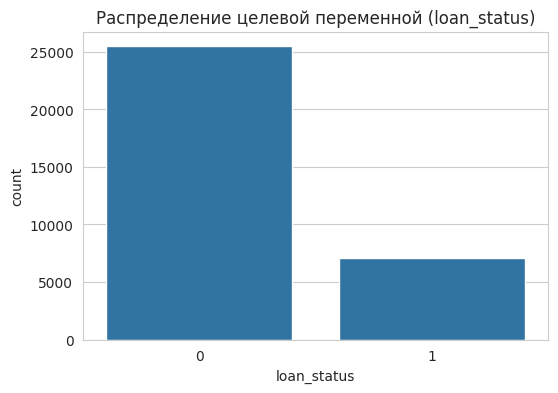

loan_status
0    0.781836
1    0.218164
Name: proportion, dtype: float64


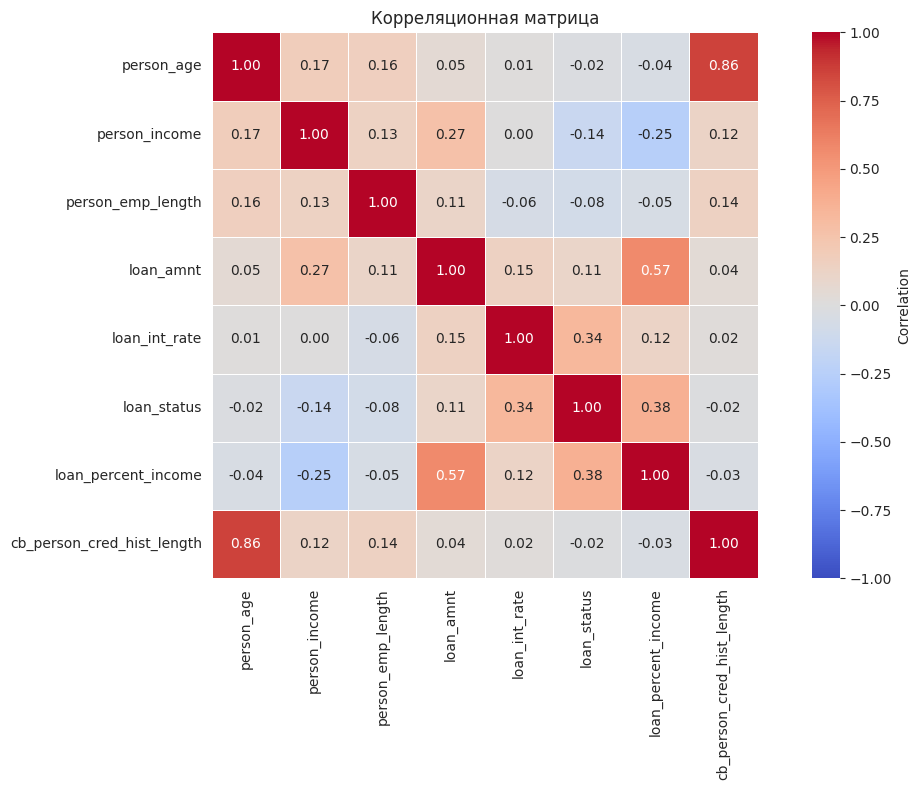

In [ ]:
# df = pd.read_csv('credit_risk_dataset.csv') # Раскомментируйте после загрузки
# Для демонстрации создадим упрощённую структуру,
# но с реальными данными все шаги будут работать так же.

# 1. Размер и типы данных
print("Размер данных:", df.shape)
print("\nТипы данных и пропуски:")
print(df.info())

# 2. Основные статистики
print("\nОписательные статистики числовых признаков:")
display(df.describe().T)

# 3. Пропущенные значения
print("\nПропущенные значения по столбцам:")
print(df.isnull().sum())

# 4. Визуализация целевой переменной (проверка на дисбаланс)
plt.figure(figsize=(6,4))
sns.countplot(x='loan_status', data=df)
plt.title('Распределение целевой переменной (loan_status)')
plt.show()
print(df['loan_status'].value_counts(normalize=True))

# 5. Корреляционная матрица для числовых признаков
plt.figure(figsize=(12, 8))
numeric_cols = df.select_dtypes(include=np.number).columns

corr = df[numeric_cols].corr()

sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',   # синий → красный
    vmin=-1,           # минимум шкалы = -1 (синий)
    vmax=1,            # максимум шкалы = +1 (красный)
    center=0,          # ноль всегда белый
    square=True,       # ячейки квадратные (опционально)
    linewidths=0.5,    # тонкие линии между ячейками (опционально)
    cbar_kws={'label': 'Correlation'}
)
plt.title('Корреляционная матрица')
plt.tight_layout()
plt.show()

In [ ]:
# Функция для цензурирования (capping) выбросов по методу IQR
def cap_outliers_iqr(df, column):
    Q1 = df[column].quantile(0.25)
    Q3 = df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    df[column] = np.where(df[column] < lower_bound, lower_bound, df[column])
    df[column] = np.where(df[column] > upper_bound, upper_bound, df[column])
    return df

# Применяем к ключевым числовым признакам
for col in ['person_age', 'person_income', 'loan_amnt']:
    if col in df.columns:
        df = cap_outliers_iqr(df, col)
        print(f"Выбросы в '{col}' обработаны.")

Выбросы в 'person_age' обработаны.
Выбросы в 'person_income' обработаны.
Выбросы в 'loan_amnt' обработаны.


In [ ]:
# Заполнение пропусков
for col in df.columns:
    if df[col].isnull().sum() > 0:
        if df[col].dtype in ['int64', 'float64']:
            df[col] = df[col].fillna(df[col].median())
            print(f"Пропуски в '{col}' заполнены медианой.")
        else:
            df[col] = df[col].fillna(df[col].mode()[0])
            print(f"Пропуски в '{col}' заполнены модой.")

Пропуски в 'person_emp_length' заполнены медианой.
Пропуски в 'loan_int_rate' заполнены медианой.


In [ ]:
# Определяем категориальные и числовые столбцы
categorical_cols = df.select_dtypes(include=['object', 'category']).columns.tolist()
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
numeric_cols.remove('loan_status') # Убираем целевую переменную

# Создаём препроцессор
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols), # Нормализация будет здесь
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ])

# Применяем преобразования ко всему датасету (или к X_train/X_test отдельно)
X = df.drop('loan_status', axis=1)
y = df['loan_status']

# Разделение на train/test ДО преобразований, чтобы избежать утечки данных
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Обучаем препроцессор только на тренировочных данных и трансформируем оба набора
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

In [ ]:
# Создаём базовую модель KNN
knn = KNeighborsClassifier(n_neighbors=5)

# Обучаем пайплайн (препроцессор + модель)
pipeline = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', knn)])

# Поскольку мы уже преобразовали данные, обучим модель напрямую
knn.fit(X_train_processed, y_train)

# Предсказания
y_train_pred = knn.predict(X_train_processed)
y_test_pred = knn.predict(X_test_processed)

=== Матрица рассогласования (тест) ===


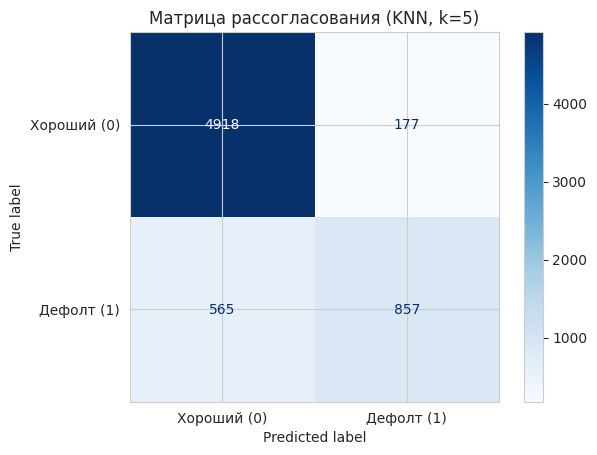


=== Отчёт по классификации (тест) ===
              precision    recall  f1-score   support

 Хороший (0)       0.90      0.97      0.93      5095
  Дефолт (1)       0.83      0.60      0.70      1422

    accuracy                           0.89      6517
   macro avg       0.86      0.78      0.81      6517
weighted avg       0.88      0.89      0.88      6517

Ошибка на обучающей выборке: 0.0817
Ошибка на тестовой выборке: 0.1139

Лучшее значение k: 9
Лучший F1-score (кросс-валидация): 0.7082

Ошибка на тесте с лучшим k: 0.1071
              precision    recall  f1-score   support

 Хороший (0)       0.90      0.97      0.93      5095
  Дефолт (1)       0.87      0.60      0.71      1422

    accuracy                           0.89      6517
   macro avg       0.88      0.79      0.82      6517
weighted avg       0.89      0.89      0.89      6517



In [ ]:
# 1. Матрица рассогласования и отчёт по классификации
print("=== Матрица рассогласования (тест) ===")
cm = confusion_matrix(y_test, y_test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Хороший (0)', 'Дефолт (1)'])
disp.plot(cmap='Blues')
plt.title('Матрица рассогласования (KNN, k=5)')
plt.show()

print("\n=== Отчёт по классификации (тест) ===")
print(classification_report(y_test, y_test_pred, target_names=['Хороший (0)', 'Дефолт (1)']))

# 2. Ошибки на train и test
train_error = 1 - accuracy_score(y_train, y_train_pred)
test_error = 1 - accuracy_score(y_test, y_test_pred)
print(f"Ошибка на обучающей выборке: {train_error:.4f}")
print(f"Ошибка на тестовой выборке: {test_error:.4f}")

# 3. Подбор оптимального k с помощью GridSearchCV
param_grid = {'classifier__n_neighbors': range(1, 31, 2)} # Нечётные значения от 1 до 30
pipeline_for_grid = Pipeline(steps=[('preprocessor', preprocessor),
                                    ('classifier', KNeighborsClassifier())])

grid_search = GridSearchCV(pipeline_for_grid, param_grid, cv=5, scoring='f1', n_jobs=-1)
grid_search.fit(X_train, y_train) # Обратите внимание: здесь используется сырой X_train, пайплайн сделает всё сам

print(f"\nЛучшее значение k: {grid_search.best_params_['classifier__n_neighbors']}")
print(f"Лучший F1-score (кросс-валидация): {grid_search.best_score_:.4f}")

# Оцениваем модель с лучшим k на тесте
best_knn = grid_search.best_estimator_
y_test_pred_best = best_knn.predict(X_test)
print(f"\nОшибка на тесте с лучшим k: {1 - accuracy_score(y_test, y_test_pred_best):.4f}")
print(classification_report(y_test, y_test_pred_best, target_names=['Хороший (0)', 'Дефолт (1)']))

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced', n_jobs=-1)
}

results = {}
for name, model in models.items():
    pipe = Pipeline(steps=[('preprocessor', preprocessor),
                           ('classifier', model)])
    pipe.fit(X_train, y_train)
    y_pred = pipe.predict(X_test)
    results[name] = {
        'Accuracy': accuracy_score(y_test, y_pred),
        'F1 (default)': f1_score(y_test, y_pred, pos_label=1),
        'Recall (default)': recall_score(y_test, y_pred, pos_label=1)
    }
    print(f"\n--- {name} ---")
    print(classification_report(y_test, y_pred, target_names=['Хороший (0)', 'Дефолт (1)']))

# Сводная таблица
print("\n=== Сводная таблица результатов на тесте ===")
results_df = pd.DataFrame(results).T
display(results_df)


--- Logistic Regression ---
              precision    recall  f1-score   support

 Хороший (0)       0.93      0.82      0.87      5095
  Дефолт (1)       0.55      0.78      0.65      1422

    accuracy                           0.81      6517
   macro avg       0.74      0.80      0.76      6517
weighted avg       0.85      0.81      0.82      6517


--- Random Forest ---
              precision    recall  f1-score   support

 Хороший (0)       0.93      1.00      0.96      5095
  Дефолт (1)       0.98      0.71      0.83      1422

    accuracy                           0.93      6517
   macro avg       0.95      0.85      0.89      6517
weighted avg       0.94      0.93      0.93      6517


=== Сводная таблица результатов на тесте ===


,Accuracy,F1 (default),Recall (default)
Logistic Regression,0.814485,0.648240,0.783404
Random Forest,0.934019,0.825203,0.713783


In [ ]:
# Применяем SMOTE к тренировочным данным (после препроцессинга)
smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_processed, y_train)

print(f"Размер до SMOTE: {X_train_processed.shape}")
print(f"Размер после SMOTE: {X_train_resampled.shape}")
print(f"Распределение классов после SMOTE:\n{pd.Series(y_train_resampled).value_counts()}")

# Обучаем KNN на сбалансированных данных
knn_balanced = KNeighborsClassifier(n_neighbors=grid_search.best_params_['classifier__n_neighbors'])
knn_balanced.fit(X_train_resampled, y_train_resampled)
y_test_pred_balanced = knn_balanced.predict(X_test_processed)

print("\n=== Результаты KNN после SMOTE ===")
print(classification_report(y_test, y_test_pred_balanced, target_names=['Хороший (0)', 'Дефолт (1)']))

Размер до SMOTE: (26064, 26)
Размер после SMOTE: (40756, 26)
Распределение классов после SMOTE:
loan_status
0    20378
1    20378
Name: count, dtype: int64

=== Результаты KNN после SMOTE ===
              precision    recall  f1-score   support

 Хороший (0)       0.93      0.82      0.87      5095
  Дефолт (1)       0.55      0.78      0.64      1422

    accuracy                           0.81      6517
   macro avg       0.74      0.80      0.76      6517
weighted avg       0.85      0.81      0.82      6517



Пары числовых признаков с |r| > 0.9:
  Таких пар не обнаружено.

Признаки, предложенные к удалению: []

Используем лучшее k = 9 (найденное ранее).
[ДО удаления]  Accuracy=0.8929 | F1(дефолт)=0.7104 | Recall(дефолт)=0.6020
[ПОСЛЕ удаления] Accuracy=0.8929 | F1(дефолт)=0.7104 | Recall(дефолт)=0.6020

=== Сравнение ===


,Accuracy,F1 (дефолт),Recall (дефолт)
Модель,,,
KNN (все признаки),0.8929,0.7104,0.602
KNN (без коррелированных),0.8929,0.7104,0.602



Матрица рассогласования (KNN без коррелированных признаков):


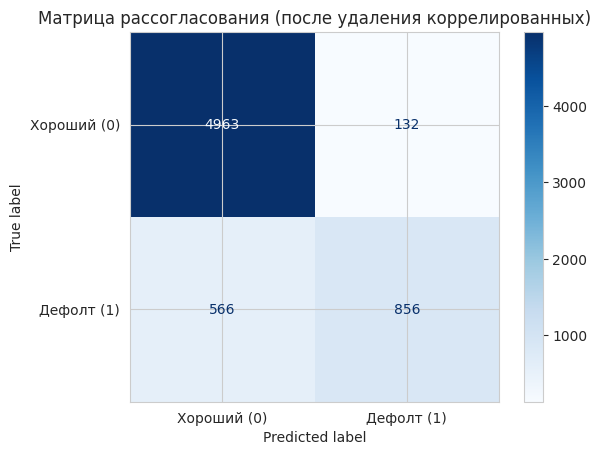

In [ ]:
# ============================================================
# Шаг 12. Борьба с мультиколлинеарностью (удаление коррелированных признаков)
# ============================================================

# --- 12.1. Считаем корреляцию ТОЛЬКО на исходных числовых признаках ---
# (one-hot признаки не включаем — у них искусственная корреляция по построению)
corr_matrix = X_train[numeric_cols].corr().abs()

# Оставляем верхний треугольник, чтобы не дублировать пары
upper = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

# --- 12.2. Смотрим, какие пары сильно коррелируют ---
threshold = 0.9
high_corr_pairs = (
    upper.stack()
         .loc[lambda s: s > threshold]
         .sort_values(ascending=False)
)
print(f"Пары числовых признаков с |r| > {threshold}:")
if len(high_corr_pairs) == 0:
    print("  Таких пар не обнаружено.")
else:
    print(high_corr_pairs.to_string())

# --- 12.3. Формируем список признаков к удалению ---
to_drop = [col for col in upper.columns if any(upper[col] > threshold)]
print(f"\nПризнаки, предложенные к удалению: {to_drop}")

# --- 12.4. Оцениваем модель БЕЗ удаления (базовая) ---
best_k = grid_search.best_params_['classifier__n_neighbors']
print(f"\nИспользуем лучшее k = {best_k} (найденное ранее).")

knn_before = KNeighborsClassifier(n_neighbors=best_k)
knn_before.fit(X_train_processed, y_train)
y_pred_before = knn_before.predict(X_test_processed)

f1_before = f1_score(y_test, y_pred_before, pos_label=1)
recall_before = recall_score(y_test, y_pred_before, pos_label=1)
acc_before = accuracy_score(y_test, y_pred_before)
print(f"[ДО удаления]  Accuracy={acc_before:.4f} | F1(дефолт)={f1_before:.4f} | Recall(дефолт)={recall_before:.4f}")

# --- 12.5. Строим новый препроцессор без удалённых признаков ---
numeric_cols_reduced = [c for c in numeric_cols if c not in to_drop]

preprocessor_reduced = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_cols_reduced),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_cols)
    ]
)

X_train_reduced = preprocessor_reduced.fit_transform(X_train)
X_test_reduced  = preprocessor_reduced.transform(X_test)

# --- 12.6. Оцениваем модель ПОСЛЕ удаления ---
knn_after = KNeighborsClassifier(n_neighbors=best_k)
knn_after.fit(X_train_reduced, y_train)
y_pred_after = knn_after.predict(X_test_reduced)

f1_after = f1_score(y_test, y_pred_after, pos_label=1)
recall_after = recall_score(y_test, y_pred_after, pos_label=1)
acc_after = accuracy_score(y_test, y_pred_after)
print(f"[ПОСЛЕ удаления] Accuracy={acc_after:.4f} | F1(дефолт)={f1_after:.4f} | Recall(дефолт)={recall_after:.4f}")

# --- 12.7. Сводная таблица ---
comparison = pd.DataFrame({
    'Модель':          ['KNN (все признаки)', 'KNN (без коррелированных)'],
    'Accuracy':        [acc_before, acc_after],
    'F1 (дефолт)':     [f1_before, f1_after],
    'Recall (дефолт)': [recall_before, recall_after],
}).set_index('Модель')
print("\n=== Сравнение ===")
display(comparison.round(4))

# --- 12.8. Матрица рассогласования для модели после удаления ---
print("\nМатрица рассогласования (KNN без коррелированных признаков):")
cm = confusion_matrix(y_test, y_pred_after)
disp = ConfusionMatrixDisplay(cm, display_labels=['Хороший (0)', 'Дефолт (1)'])
disp.plot(cmap='Blues')
plt.title('Матрица рассогласования (после удаления коррелированных)')
plt.show()